In [2]:
using MAT
acc= matread("/home/plusultra/sim/Kalman_filter_tutorial/ArsAccel.mat")
gyro= matread("/home/plusultra/sim/Kalman_filter_tutorial/ArsGyro.mat")

w3=gyro["wz"]
w1=gyro["wx"]
w2=gyro["wy"]

fx=acc["fx"]
fy=acc["fy"]
fz=acc["fz"]

w=[w1 w2 w3]
#println(keys(acc))

41500×3 Matrix{Float64}:
  0.000159785   0.00223706    0.0014381
  0.000159785   0.00319579   -0.00335559
  0.00319579   -0.000958744  -0.00191747
  0.000639157  -0.0015979    -0.0014381
  0.000159785   0.00127831    0.000319587
 -0.00415453    0.00271643    0.0014381
 -0.00127831    0.00671116    0.00479369
  0.00383496    0.00175769    0.00127831
 -0.000159785   0.00223706   -0.000958744
  0.00223706    0.000319587  -0.00191747
 -0.000159785   0.00175769    0.00335559
 -0.000639157   0.00127831    0.00431431
 -0.00319579    0.00479369   -0.000479372
  ⋮                          
 -0.00271643    0.00271643    0.00575243
  0.00223706    0.00111853    0.00319579
 -0.000319587   0.00255663    0.000319587
  0.000639157   0.00367516    0.000798942
 -0.00127831    0.00511327   -0.003036
 -0.00287622    0.00207727    0.000798942
  0.00591222   -0.000958744   0.00287622
 -0.00335559    0.00319579    0.000319587
  0.00111853    0.00175769    0.00383496
  0.000639157   0.00319579    0.00527306


In [19]:
#initialisation for plain integration

function euler_kde(y,w,t)
    
    b0=y[1]
    b1=y[2]
    b2=y[3]
    b3=y[4]

    B = [-b1 -b2 -b3 ; b0 -b3  b2 ; b3  b0 -b1 ;-b2  b1  b0 ]

    beta_dot = 0.5*B*w(t) 

    return ydot = beta_dot

end

Nsamples = 41500
dt = 0.01
tf = Nsamples*dt-dt
psi = 0 
theta=0 
phi = 0 

wt = 0:dt:tf
y0=[1 0 0 0]' #initialising for quaternions
y0 = vec(y0)

#size(g(0.02))

using DataInterpolations
interp_w= LinearInterpolation(w',wt)

using DifferentialEquations
prob = ODEProblem(euler_kde, y0,(0,tf),interp_w)

sol = solve(prob)


retcode: Success
Interpolation: 3rd order Hermite
t: 4797-element Vector{Float64}:
   0.0
   0.03824500980892041
   0.05724977376408327
   0.08040858387064356
   0.09771019166076945
   0.12262890312455142
   0.14196378367824936
   0.16546105397684943
   0.1860905269853939
   0.20899684619146983
   0.23214841303873762
   0.25852703951611383
   0.2818862651892719
   ⋮
 414.02887370391414
 414.1180237087589
 414.216444815868
 414.3194926638096
 414.4126083672629
 414.48345647137353
 414.55278539482055
 414.61968187222243
 414.72772134041145
 414.81809511656036
 414.9297531289079
 414.99
u: 4797-element Vector{Vector{Float64}}:
 [1.0, 0.0, 0.0, 0.0]
 [0.9999999991027116, 1.323312361524283e-5, 1.537430713994878e-5, -3.431410371529015e-5]
 [0.9999999987802605, -6.5085995173778475e-6, 4.183045254914751e-5, -1.9686433439466252e-5]
 [0.9999999956477801, 1.0905913466006307e-5, 8.00822988309396e-5, 3.0751326579498176e-6]
 [0.9999999946509013, 2.026071163718577e-5, 9.004002078347365e-5, -2.2722393

In [26]:
q=sol.u
t=sol.t
using Rotations
function quat2euler_rot(q)
    r = RotZYX(QuatRotation(q[1], q[2], q[3], q[4]))   # (w, x, y, z), normalizes by default
    return [r.theta3, r.theta2, r.theta1]              # roll, pitch, yaw (rad)
end

angles = reduce(hcat, quat2euler_rot.(sol.u))'         # N×3: roll, pitch, yaw
angles_deg = rad2deg.(angles)



4797×3 Matrix{Float64}:
  0.0          -0.0          0.0
  0.00151634    0.00176182  -0.00393208
 -0.000745925   0.0047934   -0.00225593
  0.00124975    0.00917675   0.000352484
  0.00232168    0.0103178   -0.00026017
  8.55743e-5    0.0146409    0.00200008
 -0.00115455    0.0168472    0.00558729
  0.000702152   0.0189555    0.00889717
  0.00236305    0.0189763    0.0109901
  0.00243203    0.0233343    0.0137321
  0.000280835   0.0265305    0.0163483
  0.000525027   0.0311778    0.018
  0.00438891    0.0330734    0.0216584
  ⋮                         
 10.0459       48.6149      25.8832
 10.0585       48.6179      25.909
 10.0738       48.612       25.9133
 10.1013       48.6164      25.925
 10.1149       48.6396      25.9356
 10.1296       48.6464      25.9521
 10.1244       48.6562      25.9636
 10.1407       48.6586      25.9909
 10.1506       48.6699      26.0066
 10.1689       48.6778      26.0178
 10.1793       48.7032      26.0282
 10.1711       48.7174      26.0325

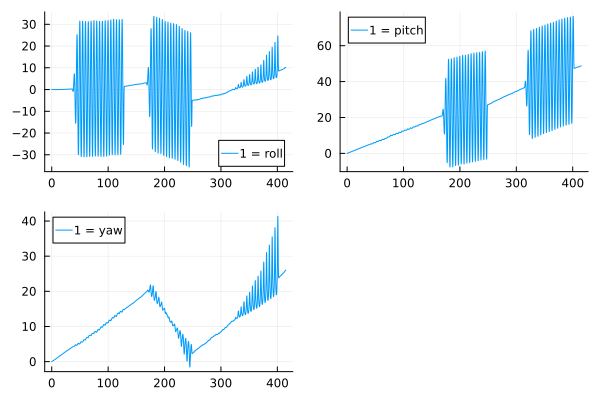

In [29]:
using Plots

p1= plot(t,angles_deg[:,1],label="1 = roll")
p2= plot(t,angles_deg[:,2],label="1 = pitch")
p3= plot(t,angles_deg[:,3],label="1 = yaw")

plot(p1,p2,p3,layout=3)

In [3]:
# kalman filter without sensor fusion
using LinearAlgebra

function kalman_filter(xs,z,p,h,A)
    xps=A*xs
    pp = A*p*A' + 0.0001*I

    k = pp*h'+inv(h*p*h'+10*I)
    xs = xps+ k*(z-h*xps)
    p =pp-k*h*pp

    return xs,p
end



#Initialisation
Nsamples = 41500
dt = 0.01
tf = Nsamples*dt-dt
psi = 0 
theta=0 
phi = 0 

wt = 0:dt:tf
xs=[1 0 0 0]'
p= I
h=I
# when x is a vector of quanternions

function A(w1,w2,w3)
    B= 0.5*[0 -w1 -w2 -w3; w1 0 w3 -w2;w2 -w3 0 w1;w3 w2 -w1 0]
    A= (I + dt*B)
    return A
end


estimate_x=[]
estimate_p=[]


for i in 1:length(w1)
    
    xs,p = kalman_filter(xs,xs,p,h,A(w[i,1],w[i,2],w[i,3]))
    push!(estimate_x,xs)
    push!(estimate_p,p)
end

com_x= reduce(hcat,estimate_x)'

using Rotations
function quat2euler_rot(q)
    r = RotZYX(QuatRotation(q[1], q[2], q[3], q[4]))   # (w, x, y, z), normalizes by default
    return [r.theta3, r.theta2, r.theta1]              # roll, pitch, yaw (rad)
end

angles = reduce(hcat, [quat2euler_rot(q) for q in eachrow(com_x)])'   # N×3
angles_deg = rad2deg.(angles)
# using Plots
# p4= plot(wt,)


41500×3 Matrix{Float64}:
 -8.33181e-6   -0.00011665   -7.49888e-5
  8.22764e-5    0.00169609   -0.00197837
  0.00189316    0.00115283   -0.00306493
  0.00225494    0.000248387  -0.00387898
  0.00234528    0.000971104  -0.00369826
 -5.88479e-7    0.00250494   -0.0028862
 -0.000721212   0.00628933   -0.000183099
  0.00143823    0.00727903    0.00053669
  0.00134833    0.00853671   -2.28322e-6
  0.00260375    0.00871612   -0.00107849
  0.00251453    0.00970083    0.000801621
  0.00215751    0.0104156     0.00321437
  0.000373778   0.0130911     0.00294687
  ⋮                          
 27.0967       23.5671       94.3625
 27.0986       23.5669       94.3644
 27.0988       23.568        94.3652
 27.0997       23.5695       94.3665
 27.0989       23.5725       94.3663
 27.0978       23.5733       94.3672
 27.1013       23.5722       94.3684
 27.1          23.5736       94.3694
 27.1015       23.5735       94.3718
 27.1032       23.5737       94.3752
 27.1015       23.5766       94.3766
 27.

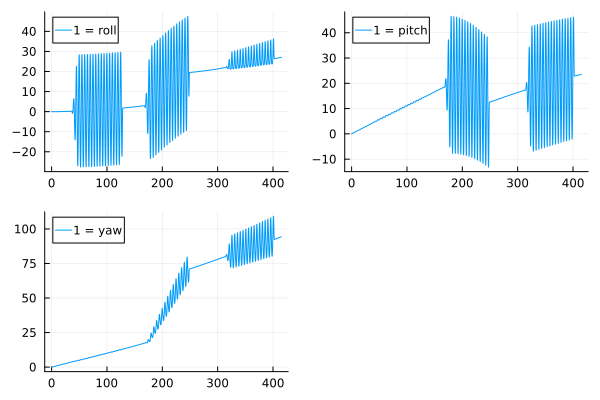

In [13]:
using Plots

p1= plot(wt,angles_deg[:,1],label="1 = roll")
p2= plot(wt,angles_deg[:,2],label="1 = pitch")
p3= plot(wt,angles_deg[:,3],label="1 = yaw")

plot(p1,p2,p3,layout=3)

In [8]:
#Initialisation

Nsamples = 41500
dt = 0.01
tf = Nsamples*dt-dt
psi = 0 
# theta=0 
# phi = 0 

wt = 0:dt:tf
xs=[1 0 0 0]'
p= I
h=I
# when x is a vector of quanternions


using Rotations

function euler2quat(phi, theta, psi)      # roll, pitch, yaw in radians
    r = RotZYX(psi, theta, phi)           # Z (yaw), Y (pitch), X (roll)
    q = QuatRotation(r)
    return [q.q.s, q.q.v1, q.q.v2, q.q.v3]   # [w, x, y, z]
end

function acc1(ax,ay)
    g = 9.8; # average of sqrt(ax^2 + ay^2 + az^2)

    theta = asin(  ax / g );
    phi   = asin( -ay / (g*cos(theta)) );  
    return theta, phi
end

estimate_sensor_fusion_x=[]
estimate_sensor_fusion_p=[]


for i in 1:length(w1)
    theta, phi = acc1(fx[i],fy[i])
    z= euler2quat(phi,theta,psi)
    xs,p = kalman_filter(xs,z,p,h,A(w[i,1],w[i,2],w[i,3]))
    r = RotZYX(QuatRotation(xs[1],xs[2],xs[3],xs[4]))
    psi= r.theta3
    push!(estimate_sensor_fusion_x,xs)
    push!(estimate_sensor_fusion_p,p)
end

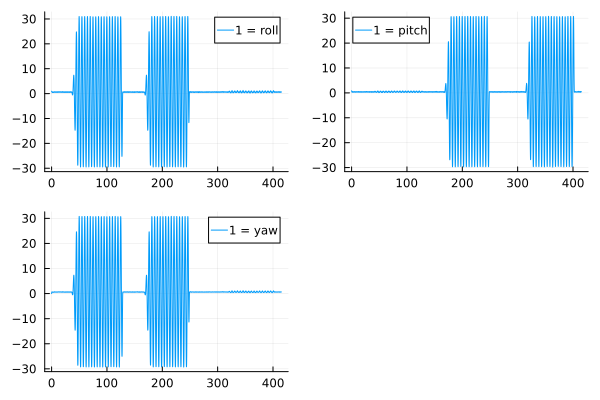

In [13]:

new_angles = reduce(hcat, [quat2euler_rot(vec(q)) for q in estimate_sensor_fusion_x])'   # N×3
new_angles_deg = rad2deg.(new_angles)

# @show size(estimate_sensor_fusion_x) typeof(estimate_sensor_fusion_x[1])
# @show estimate_sensor_fusion_x[1]

using Plots

p1= plot(wt,new_angles_deg[:,1],label="1 = roll")
p2= plot(wt,new_angles_deg[:,2],label="1 = pitch")
p3= plot(wt,new_angles_deg[:,3],label="1 = yaw")

plot(p1,p2,p3,layout=3)